# Task 3: Content-based recommendation system (Netflix titles)

**DRAFT. Run it, understand each step, and rewrite the text in your own words.**

Data: `netflix_clean.csv` (the Task 1 output, 8,787 titles). It is read from this folder, or from the parent folder (the repo root) if it is not here.

Workflow: features, preprocessing, similarity, recommendations, evaluation.

**Honest limit:** this model uses content features only (no viewing data), so it finds similar titles, not taste-based picks. Task 1 dropped the original description and cast columns, so the model does not know the plot or actors.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)
def save(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150)
    plt.show()

csv = "netflix_clean.csv" if os.path.exists("netflix_clean.csv") else "../netflix_clean.csv"
df = pd.read_csv(csv).reset_index(drop=True)
df["director"] = df["director"].fillna("")
print(df.shape)

(8787, 20)


## 1. Features
Each title becomes one text "soup" made of: type, genres, director, country, rating and release year. Genres and director are repeated twice so they count double. This weighting is my choice, so try other weights.

In [2]:
def tokens(text):
    # "Dramas, Comedies" -> "dramas comedies"; "United States" -> "unitedstates"
    return [p.strip().lower().replace(" ", "").replace("&", "and").replace("-", "")
            for p in str(text).split(",") if p.strip() and str(text) != "nan"]

def soup(r):
    genres = tokens(r["listed_in"])
    director = tokens(r["director"])
    parts = [r["type"].lower().replace(" ", "")]
    parts += genres * 2
    parts += director * 2
    parts += tokens(r["country"])
    parts += tokens(r["rating"])
    parts += [str(r["release_year"])]
    return " ".join(parts)

df["soup"] = df.apply(soup, axis=1)
df[["title", "soup"]].head(3)

,title,soup
0,Dick Johnson Is Dead,movie documentaries documentaries kirstenjohns...
1,Ganglands,tvshow crimetvshows internationaltvshows tvact...
2,Midnight Mass,tvshow tvdramas tvhorror tvmysteries tvdramas ...


## 2. Preprocessing: TF-IDF
TF-IDF gives rare words (a specific director) more weight than common ones (the word `movie`).

In [3]:
tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform(df["soup"])
print(matrix.shape)

(8787, 5338)


## 3. Similarity
Cosine similarity compares two titles by the angle between their vectors: 1 means identical features, 0 means nothing in common.

In [4]:
sim = linear_kernel(matrix, matrix)
print(sim.shape)
index_of = pd.Series(df.index, index=df["title"].str.lower()).groupby(level=0).first()

(8787, 8787)


## 4. Recommendations

In [5]:
def recommend(title, n=10):
    key = title.lower()
    if key not in index_of:
        raise KeyError(f"'{title}' not found")
    i = index_of[key]
    scores = sim[i].copy()
    scores[i] = -1  # never recommend the title itself
    top = np.argsort(-scores)[:n]
    out = df.loc[top, ["title", "type", "primary_genre", "country", "release_year"]].copy()
    out["similarity"] = scores[top].round(3)
    return out

recommend("Dick Johnson Is Dead")

,title,type,primary_genre,country,release_year,similarity
7308,Crip Camp: A Disability Revolution,Movie,Documentaries,United States,2020,0.329
7265,Murder to Mercy: The Cyntoia Brown Story,Movie,Documentaries,United States,2020,0.321
6823,Elizabeth and Margaret: Love and Loyalty,Movie,Documentaries,United Kingdom,2020,0.274
235,Ya no estoy aquí: Una conversación entre Guill...,Movie,Documentaries,Pakistan,2020,0.269
8046,Liberated: The New Sexual Revolution,Movie,Documentaries,United States,2017,0.266
7437,The Irishman: In Conversation,Movie,Documentaries,United States,2019,0.266
7936,Reversing Roe,Movie,Documentaries,United States,2018,0.264
7289,Surviving R. Kelly: The Impact,Movie,Documentaries,United States,2019,0.263
6903,Creating The Queen's Gambit,Movie,Documentaries,United States,2021,0.258
6919,The Minimalists: Less Is Now,Movie,Documentaries,United States,2021,0.258


In [6]:
recommend("The Crown")

,title,type,primary_genre,country,release_year,similarity
7317,The English Game,TV Show,British TV Shows,United Kingdom,2020,0.977
7396,Dracula,TV Show,British TV Shows,United Kingdom,2020,0.977
7796,Black Earth Rising,TV Show,British TV Shows,United Kingdom,2018,0.954
8023,Requiem,TV Show,British TV Shows,United Kingdom,2018,0.954
7742,Traitors,TV Show,British TV Shows,United Kingdom,2019,0.953
7674,Black Mirror,TV Show,British TV Shows,United Kingdom,2019,0.953
6864,Behind Her Eyes,TV Show,British TV Shows,United Kingdom,2021,0.944
6747,Downton Abbey,TV Show,British TV Shows,United Kingdom,2015,0.921
6687,The A List,TV Show,British TV Shows,United Kingdom,2021,0.911
8532,Land Girls,TV Show,British TV Shows,United Kingdom,2011,0.901


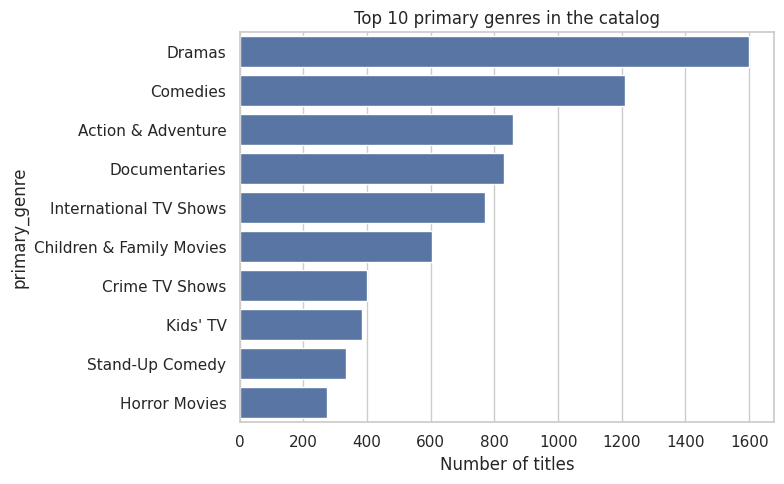

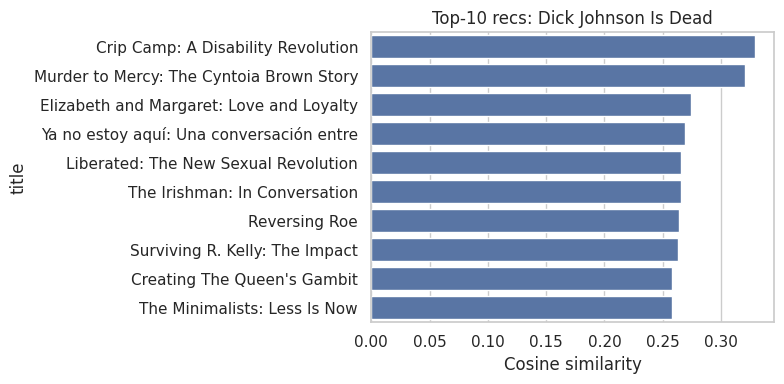

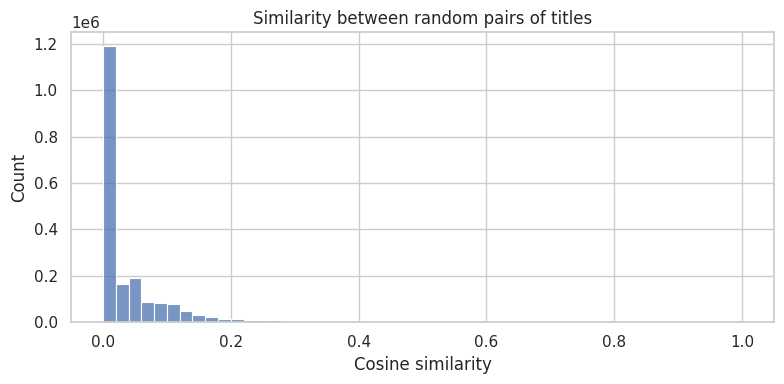

In [7]:
top_g = df["primary_genre"].value_counts().head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=top_g.values, y=top_g.index)
plt.title("Top 10 primary genres in the catalog")
plt.xlabel("Number of titles")
save("01_top_genres")

demo = recommend("Dick Johnson Is Dead")
plt.figure(figsize=(8, 4))
sns.barplot(x=demo["similarity"], y=demo["title"].str.slice(0, 40))
plt.title("Top-10 recs: Dick Johnson Is Dead")
plt.xlabel("Cosine similarity")
save("02_sample_recommendations")

rng = np.random.default_rng(0)
sample_idx = rng.choice(len(df), 2000, replace=False)
vals = sim[np.ix_(sample_idx, sample_idx)]
vals = vals[np.triu_indices_from(vals, k=1)]
plt.figure(figsize=(8, 4))
sns.histplot(vals, bins=50)
plt.title("Similarity between random pairs of titles")
plt.xlabel("Cosine similarity")
save("03_similarity_distribution")

## 5. Evaluation
There are no user ratings, so I use a simple check: for 300 random titles, do the top-10 recommendations share the title's primary genre? I compare against picking 10 random titles.

               metric  recommender  random
0  Same primary genre        0.843   0.093
1     Share any genre        0.983   0.238


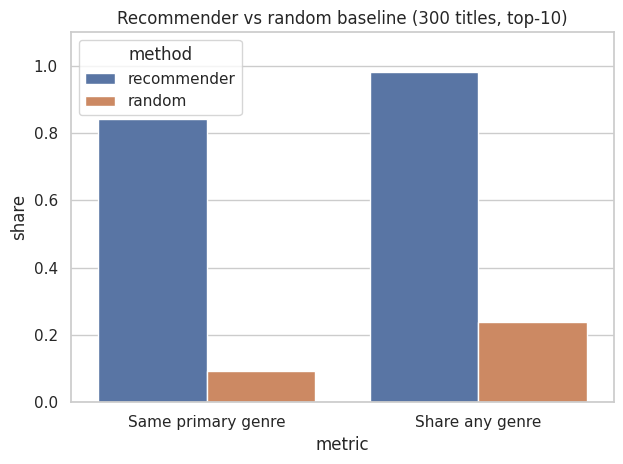

In [8]:
rng = np.random.default_rng(42)
sample = rng.choice(len(df), 300, replace=False)
pg = df["primary_genre"].values
genre_sets = df["listed_in"].str.split(",").apply(lambda g: {x.strip() for x in g}).values

hit_rec, hit_rand, any_rec, any_rand = [], [], [], []
for i in sample:
    s = sim[i].copy(); s[i] = -1
    top = np.argsort(-s)[:10]
    rand = rng.choice(np.delete(np.arange(len(df)), i), 10, replace=False)
    hit_rec.append(np.mean(pg[top] == pg[i]));  hit_rand.append(np.mean(pg[rand] == pg[i]))
    any_rec.append(np.mean([bool(genre_sets[j] & genre_sets[i]) for j in top]))
    any_rand.append(np.mean([bool(genre_sets[j] & genre_sets[i]) for j in rand]))

res = pd.DataFrame({"metric": ["Same primary genre", "Share any genre"],
                    "recommender": [np.mean(hit_rec), np.mean(any_rec)],
                    "random": [np.mean(hit_rand), np.mean(any_rand)]})
print(res.round(3))
res.melt(id_vars="metric", var_name="method", value_name="share").pipe(
    lambda d: sns.barplot(data=d, x="metric", y="share", hue="method"))
plt.title("Recommender vs random baseline (300 titles, top-10)")
plt.ylim(0, 1.1)
save("04_evaluation")

Note: the primary genre is also part of the features, so this check is partly circular. It shows the model finds similar content, not that people would enjoy it. **[Explain this limit in your words.]**

## Data caveats
- The cleaned file ends 25 Sep 2021.
- One country label per title.
- 14 titles have a negative release-to-addition lag (flagged in Task 2).
- Task 1 dropped the description and cast columns. Adding them back is a natural improvement.

## Findings summary (rewrite in your own words)

- [Method: TF-IDF on genres, director, type, country, rating, year; cosine similarity; top 10.]
- [Result: about 84% of top-10 recommendations share the primary genre vs about 9% random, and about 98% share any genre vs about 24%; check the numbers in your own run.]
- [Demo: what the recommendations for the two sample titles look like.]
- [Limits: content-only, no viewing data, no description/cast, partly circular evaluation.]
- [Improvement idea: merge description and cast back in.]